In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("RetailPulse Day 2 environment ready!")


RetailPulse Day 2 environment ready!


In [2]:
import os

file_path = r"C:\Users\shubhAM\Desktop\RetailPulse_ZIDIO_INTERNSHIP\online_retail_II.xlsx"

print("Resolved file_path:", file_path)
print("File exists:", os.path.exists(file_path))


Resolved file_path: C:\Users\shubhAM\Desktop\RetailPulse_ZIDIO_INTERNSHIP\online_retail_II.xlsx
File exists: True


In [3]:
excel_file = pd.ExcelFile(file_path)
print(excel_file.sheet_names)

df_2009 = pd.read_excel(file_path, sheet_name='Year 2009-2010')
df_2010 = pd.read_excel(file_path, sheet_name='Year 2010-2011')
df = pd.concat([df_2009, df_2010], ignore_index=True)

['Year 2009-2010', 'Year 2010-2011']


In [ ]:

# Load both sheets
df_2009 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

# Combine the sheets
df_raw = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

# Create our engineered feature
df_raw["Revenue"] = df_raw["Quantity"] * df_raw["Price"]

print("Raw dataset loaded:", df_raw.shape)
display(df_raw.head())


In [ ]:

# 1. Check dataset dimensions
print("Dataset shape:", df_raw.shape)

# 2. Check column names
print("\nColumns:")
print(df_raw.columns.tolist())

# 3. Check data types and non-null counts
print("\nDataset information:")
df_raw.info()

# 4. Check missing values
print("\nMissing values:")
display(df_raw.isnull().sum().to_frame("Missing Count"))

# 5. Check duplicate rows
print("\nExact duplicate rows:", df_raw.duplicated().sum())

# 6. Check Revenue calculation
print("\nRevenue verification:")
print(
    "All revenue values match Quantity × Price:",
    np.allclose(
        df_raw["Revenue"],
        df_raw["Quantity"] * df_raw["Price"],
        equal_nan=True
    )
)


Dataset shape: (1067371, 9)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
 8   Revenue      1067371 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 73.3+ MB

Missing values:


,Missing Count
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0
Revenue,0



Exact duplicate rows: 34335

Revenue verification:
All revenue values match Quantity × Price: True


: 

In [ ]:

# Keep df_raw unchanged.
# Inspect exact duplicates without removing anything.

duplicate_mask = df_raw.duplicated(keep=False)

duplicate_rows = df_raw.loc[duplicate_mask].copy()

print("Rows belonging to duplicate groups:", len(duplicate_rows))
print("Exact duplicate rows after the first occurrence:",
      df_raw.duplicated().sum())

# Examine duplicate groups with their occurrence counts
duplicate_groups = (
    df_raw.groupby(df_raw.columns.tolist(), dropna=False)
    .size()
    .reset_index(name="Occurrences")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["Occurrences"] > 1
].sort_values("Occurrences", ascending=False)

print("\nNumber of repeated row patterns:", len(duplicate_groups))
display(duplicate_groups.head(10))


Rows belonging to duplicate groups: 67242
Exact duplicate rows after the first occurrence: 34335

Number of repeated row patterns: 32907


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Occurrences
694118,555524,22698,PINK REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,2.95,20
694117,555524,22697,GREEN REGENCY TEACUP AND SAUCER,1,2011-06-05 11:37:00,2.95,16923.0,United Kingdom,2.95,12
496282,537224,70007,HI TEC ALPINE HAND WARMER,1,2010-12-05 16:24:00,1.65,13174.0,United Kingdom,1.65,10
895184,572861,22775,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN,12,2011-10-26 12:46:00,1.25,14102.0,United Kingdom,15.00,8
499324,537422,22585,PACK OF 6 BIRDY GIFT TAGS,2,2010-12-06 15:27:00,1.25,17812.0,United Kingdom,2.50,6
497951,537265,79000,MOROCCAN TEA GLASS,12,2010-12-06 11:26:00,0.85,15919.0,United Kingdom,10.20,6
495167,537154,22727,ALARM CLOCK BAKELIKE RED,1,2010-12-05 13:05:00,3.75,15808.0,United Kingdom,3.75,6
490562,536749,22174,PHOTO CUBE,2,2010-12-02 13:49:00,1.65,17976.0,United Kingdom,3.30,6
495023,537144,21882,SKULLS TAPE,1,2010-12-05 13:00:00,0.65,15880.0,United Kingdom,0.65,6
461739,534219,35953,FOLKART STAR CHRISTMAS DECORATIONS,1,2010-11-21 16:13:00,1.25,13230.0,United Kingdom,1.25,6


: 

In [ ]:

# Summarize customer-ID availability
customer_id_summary = (
    df_raw.assign(
        Customer_ID_Status=np.where(
            df_raw["Customer ID"].isna(),
            "Missing",
            "Present"
        )
    )
    .groupby("Customer_ID_Status")
    .agg(
        Rows=("Invoice", "size"),
        Revenue_Sum=("Revenue", "sum")
    )
)

customer_id_summary["Percentage_of_Rows"] = (
    customer_id_summary["Rows"] / len(df_raw) * 100
).round(2)

display(customer_id_summary)


,Rows,Revenue_Sum,Percentage_of_Rows
Customer_ID_Status,,,
Missing,243007,2.638958e+06,22.77
Present,824364,1.664829e+07,77.23


: 

In [ ]:

# Step 1: Record the raw baseline
raw_rows = len(df_raw)
raw_revenue = df_raw["Revenue"].sum()

# Step 2: Create a separate candidate dataset
df_clean = df_raw.drop_duplicates().copy()

# Step 3: Compare before and after
clean_rows = len(df_clean)
clean_revenue = df_clean["Revenue"].sum()

print("DATA CLEANING SUMMARY")
print("Raw rows:", raw_rows)
print("Rows after exact-duplicate removal:", clean_rows)
print("Rows removed:", raw_rows - clean_rows)

print("\nREVENUE COMPARISON")
print("Raw recorded revenue:", round(raw_revenue, 2))
print("After duplicate removal:", round(clean_revenue, 2))
print("Difference:", round(raw_revenue - clean_revenue, 2))

print("\nVALIDATION")
print("Remaining exact duplicates:", df_clean.duplicated().sum())
print("Raw dataset unchanged:", len(df_raw) == raw_rows)


DATA CLEANING SUMMARY
Raw rows: 1067371
Rows after exact-duplicate removal: 1033036
Rows removed: 34335

REVENUE COMPARISON
Raw recorded revenue: 19287250.57
After duplicate removal: 18855533.7
Difference: 431716.87

VALIDATION
Remaining exact duplicates: 0
Raw dataset unchanged: True


: 

In [ ]:

# Investigate unusual transaction values
print("NEGATIVE QUANTITIES")
print("Rows:", (df_clean["Quantity"] < 0).sum())

print("\nZERO QUANTITIES")
print("Rows:", (df_clean["Quantity"] == 0).sum())

print("\nNEGATIVE PRICES")
print("Rows:", (df_clean["Price"] < 0).sum())

print("\nZERO PRICES")
print("Rows:", (df_clean["Price"] == 0).sum())

print("\nNEGATIVE QUANTITY WITH CANCELLATION INVOICE")
cancellation_mask = (
    df_clean["Invoice"].astype(str).str.startswith("C")
)
negative_quantity_mask = df_clean["Quantity"] < 0

print(
    "Rows:",
    (cancellation_mask & negative_quantity_mask).sum()
)

print("\nSAMPLE NEGATIVE-QUANTITY TRANSACTIONS")
display(
    df_clean.loc[
        negative_quantity_mask,
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price",
         "Customer ID", "Revenue"]
    ].head(10)
)

print("\nSAMPLE ZERO-PRICE TRANSACTIONS")
display(
    df_clean.loc[
        df_clean["Price"] == 0,
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price",
         "Customer ID", "Revenue"]
    ].head(10)
)


NEGATIVE QUANTITIES
Rows: 22496

ZERO QUANTITIES
Rows: 0

NEGATIVE PRICES
Rows: 5

ZERO PRICES
Rows: 6014

NEGATIVE QUANTITY WITH CANCELLATION INVOICE
Rows: 19103

SAMPLE NEGATIVE-QUANTITY TRANSACTIONS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Revenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,-17.00
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,-12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,-35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,-15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,-15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,-20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,-35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,-12.75



SAMPLE ZERO-PRICE TRANSACTIONS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Revenue
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,-0.0
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,-0.0
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,-0.0
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,-0.0
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,-0.0
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,0.0
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,-0.0
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,-0.0
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,0.0
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,-0.0


: 

In [ ]:

# 1. Compare negative quantities with cancellation invoices
invoice_is_cancellation = (
    df_clean["Invoice"].astype(str).str.startswith("C")
)
quantity_is_negative = df_clean["Quantity"] < 0

print("NEGATIVE QUANTITY CLASSIFICATION")
print(
    "Negative quantity + C invoice:",
    (quantity_is_negative & invoice_is_cancellation).sum()
)
print(
    "Negative quantity without C invoice:",
    (quantity_is_negative & ~invoice_is_cancellation).sum()
)

# 2. Inspect negative quantities without a C prefix
print("\nSAMPLE NEGATIVE QUANTITIES WITHOUT C PREFIX")

display(
    df_clean.loc[
        quantity_is_negative & ~invoice_is_cancellation,
        [
            "Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price",
            "Customer ID", "Country", "Revenue"
        ]
    ].head(15)
)

# 3. Group zero-price transactions by description
print("\nZERO-PRICE TRANSACTIONS BY DESCRIPTION")

zero_price_summary = (
    df_clean.loc[df_clean["Price"] == 0]
    .groupby("Description", dropna=False)
    .agg(
        Rows=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Rows", ascending=False)
)

display(zero_price_summary.head(20))

# 4. Inspect negative-price transactions
print("\nNEGATIVE-PRICE TRANSACTIONS")

display(
    df_clean.loc[
        df_clean["Price"] < 0,
        [
            "Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price",
            "Customer ID", "Revenue"
        ]
    ]
)


NEGATIVE QUANTITY CLASSIFICATION
Negative quantity + C invoice: 19103
Negative quantity without C invoice: 3393

SAMPLE NEGATIVE QUANTITIES WITHOUT C PREFIX


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,-0.0
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,-0.0
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,-0.0
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,-0.0
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,-0.0
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,-0.0
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,-0.0
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,-0.0
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom,-0.0
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom,-0.0



ZERO-PRICE TRANSACTIONS BY DESCRIPTION


,Rows,Total_Quantity
Description,,
NaN,4275,-74243
check,160,-12057
?,90,-26004
damages,83,-8083
damaged,81,-4419
found,28,2136
missing,27,-16467
sold as set on dotcom,20,-2393
Damaged,17,-8013



NEGATIVE-PRICE TRANSACTIONS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,-38925.87
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,-11062.06
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,-11062.06


: 

In [ ]:

# Create a working copy of the candidate dataset
df_work = df_clean.copy()

# 1. Identify cancellation invoices
df_work["Is_Cancellation_Invoice"] = (
    df_work["Invoice"].astype(str).str.startswith("C")
)

# 2. Identify negative quantities
df_work["Is_Negative_Quantity"] = (
    df_work["Quantity"] < 0
)

# 3. Identify zero-price records
df_work["Is_Zero_Price"] = (
    df_work["Price"] == 0
)

# 4. Identify negative-price records
df_work["Is_Negative_Price"] = (
    df_work["Price"] < 0
)

# 5. Identify missing customer IDs
df_work["Has_Customer_ID"] = (
    df_work["Customer ID"].notna()
)

# 6. Identify likely accounting adjustments
df_work["Is_Bad_Debt_Adjustment"] = (
    df_work["Description"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .eq("adjust bad debt")
    .fillna(False)
)

# 7. Summarize the flags
flag_columns = [
    "Is_Cancellation_Invoice",
    "Is_Negative_Quantity",
    "Is_Zero_Price",
    "Is_Negative_Price",
    "Has_Customer_ID",
    "Is_Bad_Debt_Adjustment"
]

print("TRANSACTION QUALITY SUMMARY")

for column in flag_columns:
    print(f"{column}: {df_work[column].sum():,}")

print("\nDATASET VALIDATION")
print("Rows:", len(df_work))
print("Columns:", len(df_work.columns))
print("Exact duplicates:", df_work.duplicated().sum())

display(
    df_work.loc[
        df_work["Is_Bad_Debt_Adjustment"],
        [
            "Invoice", "StockCode", "Description",
            "Quantity", "Price", "Revenue",
            "Is_Negative_Price"
        ]
    ]
)


TRANSACTION QUALITY SUMMARY
Is_Cancellation_Invoice: 19,104
Is_Negative_Quantity: 22,496
Is_Zero_Price: 6,014
Is_Negative_Price: 5
Has_Customer_ID: 797,885
Is_Bad_Debt_Adjustment: 6

DATASET VALIDATION
Rows: 1033036
Columns: 15
Exact duplicates: 0


,Invoice,StockCode,Description,Quantity,Price,Revenue,Is_Negative_Price
179403,A506401,B,Adjust bad debt,1,-53594.36,-53594.36,True
276274,A516228,B,Adjust bad debt,1,-44031.79,-44031.79,True
403472,A528059,B,Adjust bad debt,1,-38925.87,-38925.87,True
825443,A563185,B,Adjust bad debt,1,11062.06,11062.06,False
825444,A563186,B,Adjust bad debt,1,-11062.06,-11062.06,True
825445,A563187,B,Adjust bad debt,1,-11062.06,-11062.06,True


: 

In [ ]:

# Keep df_work unchanged and create a sales-analysis copy
df_sales = df_work.copy()

# Identify ordinary product transactions
df_sales["Is_Ordinary_Product_Sale"] = (
    (df_sales["Quantity"] > 0)
    & (df_sales["Price"] > 0)
    & (~df_sales["Is_Bad_Debt_Adjustment"])
)

# Count the different transaction categories
print("SALES ANALYSIS SUMMARY")

print(
    "Total rows:",
    len(df_sales)
)

print(
    "Ordinary product-sale rows:",
    df_sales["Is_Ordinary_Product_Sale"].sum()
)

print(
    "Rows excluded from ordinary product sales:",
    (~df_sales["Is_Ordinary_Product_Sale"]).sum()
)

print("\nREVENUE COMPARISON")

print(
    "Revenue across all candidate-cleaned records:",
    round(df_sales["Revenue"].sum(), 2)
)

print(
    "Revenue from ordinary product-sale rows:",
    round(
        df_sales.loc[
            df_sales["Is_Ordinary_Product_Sale"],
            "Revenue"
        ].sum(),
        2
    )
)

print("\nVALIDATION")

print(
    "Rows in df_work:",
    len(df_work)
)

print(
    "Rows in df_sales:",
    len(df_sales)
)

print(
    "Original candidate dataset unchanged:",
    len(df_work) == 1033036
)


SALES ANALYSIS SUMMARY
Total rows: 1033036
Ordinary product-sale rows: 1007913
Rows excluded from ordinary product sales: 25123

REVENUE COMPARISON
Revenue across all candidate-cleaned records: 18855533.7
Revenue from ordinary product-sale rows: 20465571.96

VALIDATION
Rows in df_work: 1033036
Rows in df_sales: 1033036
Original candidate dataset unchanged: True


: 

In [ ]:

# Revenue reconciliation: included vs excluded records

included_mask = df_sales["Is_Ordinary_Product_Sale"]
excluded_mask = ~included_mask

included_revenue = df_sales.loc[included_mask, "Revenue"].sum()
excluded_revenue = df_sales.loc[excluded_mask, "Revenue"].sum()
total_revenue = df_sales["Revenue"].sum()

print("REVENUE RECONCILIATION")
print("Included revenue:", round(included_revenue, 2))
print("Excluded revenue:", round(excluded_revenue, 2))
print("Combined revenue:", round(included_revenue + excluded_revenue, 2))
print("Actual total revenue:", round(total_revenue, 2))
print(
    "Reconciliation passed:",
    np.isclose(included_revenue + excluded_revenue, total_revenue)
)

# Inspect excluded records by transaction characteristics
print("\nEXCLUDED RECORDS BY QUANTITY AND PRICE")

excluded_summary = (
    df_sales.loc[excluded_mask]
    .assign(
        Quantity_Type=np.select(
            [
                df_sales.loc[excluded_mask, "Quantity"] < 0,
                df_sales.loc[excluded_mask, "Quantity"] == 0
            ],
            ["Negative quantity", "Zero quantity"],
            default="Positive quantity"
        ),
        Price_Type=np.select(
            [
                df_sales.loc[excluded_mask, "Price"] < 0,
                df_sales.loc[excluded_mask, "Price"] == 0
            ],
            ["Negative price", "Zero price"],
            default="Positive price"
        )
    )
    .groupby(["Quantity_Type", "Price_Type"], dropna=False)
    .agg(
        Rows=("Revenue", "size"),
        Revenue=("Revenue", "sum")
    )
    .reset_index()
)

display(excluded_summary)


REVENUE RECONCILIATION
Included revenue: 20465571.96
Excluded revenue: -1610038.26
Combined revenue: 18855533.7
Actual total revenue: 18855533.7
Reconciliation passed: True

EXCLUDED RECORDS BY QUANTITY AND PRICE


,Quantity_Type,Price_Type,Rows,Revenue
0,Negative quantity,Positive price,19103,-1462424.18
1,Negative quantity,Zero price,3393,0.00
2,Positive quantity,Negative price,5,-158676.14
3,Positive quantity,Positive price,1,11062.06
4,Positive quantity,Zero price,2621,0.00


: 

In [ ]:

# Missing-value analysis on the working dataset

missing_summary = pd.DataFrame({
    "Missing_Count": df_work.isna().sum(),
    "Missing_Percentage": (
        df_work.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing_Count",
    ascending=False
)

print("MISSING VALUES BY COLUMN")
display(missing_summary)

# Inspect missing descriptions
print("\nROWS WITH MISSING DESCRIPTIONS")

display(
    df_work.loc[
        df_work["Description"].isna(),
        [
            "Invoice", "StockCode", "Quantity",
            "InvoiceDate", "Price", "Customer ID",
            "Country", "Revenue"
        ]
    ].head(10)
)

# Compare customer ID availability by transaction type
print("\nCUSTOMER ID AVAILABILITY")

customer_id_summary = (
    df_work.groupby(
        df_work["Customer ID"].isna()
    )
    .agg(
        Rows=("Invoice", "size"),
        Revenue=("Revenue", "sum")
    )
    .rename(index={
        True: "Customer ID missing",
        False: "Customer ID present"
    })
)

display(customer_id_summary)


MISSING VALUES BY COLUMN


,Missing_Count,Missing_Percentage
Customer ID,235151,22.76
Description,4275,0.41
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Revenue,0,0.00
Is_Cancellation_Invoice,0,0.00



ROWS WITH MISSING DESCRIPTIONS


,Invoice,StockCode,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
470,489521,21646,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,-0.0
3114,489655,20683,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,-0.0
3161,489659,21350,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,0.0
3731,489781,84292,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,0.0
4296,489806,18010,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,-0.0
4566,489821,85049G,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom,-0.0
6378,489882,35751C,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom,0.0
6555,489898,79323G,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom,0.0
6576,489901,21098,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom,-0.0
6581,489903,21166,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom,0.0



CUSTOMER ID AVAILABILITY


,Rows,Revenue
Customer ID,,
Customer ID present,797885,1.628999e+07
Customer ID missing,235151,2.565542e+06


: 

In [ ]:

# Check whether product codes can help recover missing descriptions

description_mapping = (
    df_work.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(
        Unique_Descriptions="nunique",
        Most_Common_Description=lambda s: s.mode().iloc[0]
    )
)

# Stock codes with only one observed non-missing description
unique_description_codes = description_mapping[
    description_mapping["Unique_Descriptions"] == 1
].index

missing_description_mask = df_work["Description"].isna()

recoverable_mask = (
    missing_description_mask
    & df_work["StockCode"].isin(unique_description_codes)
)

print("DESCRIPTION INVESTIGATION")
print(
    "Rows with missing descriptions:",
    missing_description_mask.sum()
)
print(
    "Missing descriptions with a single known description for StockCode:",
    recoverable_mask.sum()
)
print(
    "Missing descriptions without a single unambiguous mapping:",
    (missing_description_mask & ~recoverable_mask).sum()
)

print("\nEXAMPLE MISSING DESCRIPTIONS WITH KNOWN PRODUCT CODES")

display(
    df_work.loc[
        recoverable_mask,
        ["StockCode", "Description", "Quantity", "Price"]
    ].head(10)
)


DESCRIPTION INVESTIGATION
Rows with missing descriptions: 4275
Missing descriptions with a single known description for StockCode: 2974
Missing descriptions without a single unambiguous mapping: 1301

EXAMPLE MISSING DESCRIPTIONS WITH KNOWN PRODUCT CODES


,StockCode,Description,Quantity,Price
3114,20683,NaN,-44,0.0
3161,21350,NaN,230,0.0
3731,84292,NaN,17,0.0
4296,18010,NaN,-770,0.0
4566,85049G,NaN,-240,0.0
6378,35751C,NaN,12,0.0
7204,21982,NaN,467,0.0
7205,21982,NaN,-1012,0.0
7559,20620,NaN,-25,0.0
8553,85064,NaN,-89,0.0


: 

In [ ]:

# Create a separate copy for description recovery
df_cleaned = df_work.copy()

# Build a mapping only for StockCodes with exactly one known description
description_mapping = (
    df_cleaned.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(
        Unique_Descriptions="nunique",
        Most_Common_Description=lambda s: s.mode().iloc[0]
    )
)

unique_description_mapping = (
    description_mapping[
        description_mapping["Unique_Descriptions"] == 1
    ]["Most_Common_Description"]
)

# Identify missing descriptions that can be recovered unambiguously
missing_description_mask = df_cleaned["Description"].isna()

recoverable_mask = (
    missing_description_mask
    & df_cleaned["StockCode"].isin(unique_description_mapping.index)
)

# Fill only those missing descriptions
df_cleaned.loc[recoverable_mask, "Description"] = (
    df_cleaned.loc[recoverable_mask, "StockCode"]
    .map(unique_description_mapping)
)

# Validate the result
print("DESCRIPTION RECOVERY RESULTS")
print("Rows before recovery:", len(df_work))
print("Descriptions recovered:", recoverable_mask.sum())
print(
    "Missing descriptions before:",
    df_work["Description"].isna().sum()
)
print(
    "Missing descriptions after:",
    df_cleaned["Description"].isna().sum()
)
print("Remaining exact duplicates:", df_cleaned.duplicated().sum())
print("Original df_work unchanged:", df_work["Description"].isna().sum() == 4275)


DESCRIPTION RECOVERY RESULTS
Rows before recovery: 1033036
Descriptions recovered: 2974
Missing descriptions before: 4275
Missing descriptions after: 1301
Remaining exact duplicates: 0
Original df_work unchanged: True


: 

In [ ]:

# Investigate missing Customer IDs after description recovery

missing_customer_mask = df_cleaned["Customer ID"].isna()

print("CUSTOMER ID INVESTIGATION")
print("Total rows:", len(df_cleaned))
print("Missing Customer IDs:", missing_customer_mask.sum())
print(
    "Rows with Customer IDs:",
    df_cleaned["Customer ID"].notna().sum()
)

print("\nTRANSACTION CHARACTERISTICS")

display(
    df_cleaned.loc[missing_customer_mask]
    .groupby(
        ["Is_Cancellation_Invoice", "Is_Negative_Quantity"],
        dropna=False
    )
    .agg(
        Transaction_Rows=("Invoice", "size"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Zero_Price_Rows=("Is_Zero_Price", "sum")
    )
    .reset_index()
)

print("\nMISSING CUSTOMER ID — SAMPLE RECORDS")

display(
    df_cleaned.loc[
        missing_customer_mask,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Revenue"
        ]
    ].head(10)
)


CUSTOMER ID INVESTIGATION
Total rows: 1033036
Missing Customer IDs: 235151
Rows with Customer IDs: 797885

TRANSACTION CHARACTERISTICS


,Is_Cancellation_Invoice,Is_Negative_Quantity,Transaction_Rows,Total_Quantity,Total_Revenue,Zero_Price_Rows
0,False,False,231044,927207,2942780.04,2551
1,False,True,3393,-569314,0.00,3393
2,True,False,1,1,373.57,0
3,True,True,713,-3844,-377611.20,0



MISSING CUSTOMER ID — SAMPLE RECORDS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Revenue
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,-0.00
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,-0.00
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,-0.00
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,-0.00
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,0.55
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,0.85
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,2.95
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,15.00
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,8.85
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,1.65


: 

In [ ]:

# Investigate cancellation-prefixed invoices

cancellation_mask = df_cleaned["Is_Cancellation_Invoice"]

print("CANCELLATION INVESTIGATION")
print("Cancellation rows:", cancellation_mask.sum())

print(
    "Unique cancellation invoices:",
    df_cleaned.loc[cancellation_mask, "Invoice"].nunique()
)

print("\nQUANTITY SIGN WITHIN CANCELLATION INVOICES")

display(
    df_cleaned.loc[cancellation_mask]
    .groupby(df_cleaned.loc[cancellation_mask, "Quantity"].gt(0).map({
        True: "Positive quantity",
        False: "Zero or negative quantity"
    }))
    .agg(
        Rows=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
)

print("\nCANCELLATION RECORDS WITH POSITIVE QUANTITY")

display(
    df_cleaned.loc[
        cancellation_mask & (df_cleaned["Quantity"] > 0),
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Revenue"
        ]
    ]
)

print("\nCANCELLATION RECORDS WITH NEGATIVE QUANTITY")

display(
    df_cleaned.loc[
        cancellation_mask & (df_cleaned["Quantity"] < 0),
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "Price",
            "Revenue"
        ]
    ].head(10)
)


CANCELLATION INVESTIGATION
Cancellation rows: 19104
Unique cancellation invoices: 8292

QUANTITY SIGN WITHIN CANCELLATION INVOICES


,Rows,Unique_Invoices,Total_Quantity,Total_Revenue
Quantity,,,,
Positive quantity,1,1,1,373.57
Zero or negative quantity,19103,8291,-476820,-1462424.18



CANCELLATION RECORDS WITH POSITIVE QUANTITY


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Revenue
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,373.57



CANCELLATION RECORDS WITH NEGATIVE QUANTITY


,Invoice,StockCode,Description,Quantity,Price,Revenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,-17.00
181,C489449,21896,POTTING SHED TWINE,-6,2.10,-12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,-35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,1.25,-15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,-15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,-20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2.95,-35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,4.25,-12.75


: 

In [ ]:

# Create a separate analysis dataset
df_analysis = df_cleaned.copy()

# Classify transaction records
df_analysis["Is_Positive_Quantity"] = df_analysis["Quantity"] > 0

df_analysis["Is_Standard_Priced_Sale"] = (
    (df_analysis["Quantity"] > 0)
    & (df_analysis["Price"] > 0)
    & (~df_analysis["Is_Bad_Debt_Adjustment"])
    & (~df_analysis["Is_Cancellation_Invoice"])
)

df_analysis["Is_Cancellation_Or_Reversal"] = (
    df_analysis["Is_Cancellation_Invoice"]
    & (df_analysis["Quantity"] < 0)
)

df_analysis["Is_Zero_Price_Adjustment"] = (
    (df_analysis["Price"] == 0)
    | (df_analysis["Quantity"] == 0)
)

df_analysis["Is_Unusual_Cancellation_Record"] = (
    df_analysis["Is_Cancellation_Invoice"]
    & (df_analysis["Quantity"] > 0)
)

# Summarize classifications
print("TRANSACTION CLASSIFICATION SUMMARY")

for column in [
    "Is_Standard_Priced_Sale",
    "Is_Cancellation_Or_Reversal",
    "Is_Zero_Price_Adjustment",
    "Is_Bad_Debt_Adjustment",
    "Is_Unusual_Cancellation_Record"
]:
    print(f"{column}: {df_analysis[column].sum():,}")

print("\nDATA VALIDATION")
print("Rows preserved:", len(df_analysis))
print("Rows in df_cleaned:", len(df_cleaned))
print("Revenue unchanged:",
      df_analysis["Revenue"].sum() == df_cleaned["Revenue"].sum())
print("Exact duplicates:", df_analysis.duplicated().sum())


TRANSACTION CLASSIFICATION SUMMARY
Is_Standard_Priced_Sale: 1,007,912
Is_Cancellation_Or_Reversal: 19,103
Is_Zero_Price_Adjustment: 6,014
Is_Bad_Debt_Adjustment: 6
Is_Unusual_Cancellation_Record: 1

DATA VALIDATION
Rows preserved: 1033036
Rows in df_cleaned: 1033036
Revenue unchanged: True
Exact duplicates: 0


: 

In [ ]:

# Validate dates and inspect transaction coverage

print("DATE VALIDATION")
print("Date column type:", df_analysis["InvoiceDate"].dtype)
print("Missing dates:", df_analysis["InvoiceDate"].isna().sum())

print(
    "Earliest transaction:",
    df_analysis["InvoiceDate"].min()
)
print(
    "Latest transaction:",
    df_analysis["InvoiceDate"].max()
)

print("\nTRANSACTION ROWS BY YEAR")

display(
    df_analysis.groupby(
        df_analysis["InvoiceDate"].dt.year
    )
    .agg(
        Transaction_Rows=("Invoice", "size"),
        Unique_Invoices=("Invoice", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Standard_Sale_Rows=("Is_Standard_Priced_Sale", "sum")
    )
    .rename_axis("Year")
    .reset_index()
)

print("\nMONTHLY TRANSACTION COVERAGE")

monthly_coverage = (
    df_analysis.set_index("InvoiceDate")
    .resample("MS")
    .agg(
        Transaction_Rows=("Invoice", "size"),
        Total_Revenue=("Revenue", "sum"),
        Standard_Sale_Rows=("Is_Standard_Priced_Sale", "sum")
    )
)

display(monthly_coverage)


DATE VALIDATION
Date column type: datetime64[ns]
Missing dates: 0
Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2011-12-09 12:50:00

TRANSACTION ROWS BY YEAR


,Year,Transaction_Rows,Unique_Invoices,Total_Revenue,Standard_Sale_Rows
0,2009,44722,2330,796648.500,43453
1,2010,493653,27423,9079583.854,480572
2,2011,494661,23875,8979301.344,483887



MONTHLY TRANSACTION COVERAGE


,Transaction_Rows,Total_Revenue,Standard_Sale_Rows
InvoiceDate,,,
2009-12-01,44722,796648.500,43453
2010-01-01,31234,622479.502,30317
2010-02-01,29058,531265.366,27952
2010-03-01,40985,763247.241,39841
2010-04-01,33647,587926.692,32858
2010-05-01,34908,613270.720,33383
2010-06-01,39469,677073.870,38391
2010-07-01,32992,573333.690,32112
2010-08-01,32939,654774.390,32109


: 

MONTHLY SALES SERIES
Number of months: 25
Missing calendar months: 0
Missing months: []

FIRST 5 MONTHS


,Recorded_Revenue,Candidate_Sales_Revenue,Transaction_Rows,Candidate_Sale_Rows
InvoiceDate,,,,
2009-12-01,796648.500,822483.950,44722,43453
2010-01-01,622479.502,651155.112,31234,30317
2010-02-01,531265.366,551504.726,29058,27952
2010-03-01,763247.241,830915.261,40985,39841
2010-04-01,587926.692,678875.252,33647,32858



LAST 5 MONTHS


,Recorded_Revenue,Candidate_Sales_Revenue,Transaction_Rows,Candidate_Sale_Rows
InvoiceDate,,,,
2011-08-01,681386.460,746779.320,35064,34263
2011-09-01,1017596.682,1056435.192,49861,48900
2011-10-01,1069368.230,1151263.730,59969,58537
2011-11-01,1456145.800,1503866.780,83343,82004
2011-12-01,432719.060,637808.330,25247,24834



MONTHLY REVENUE COMPARISON


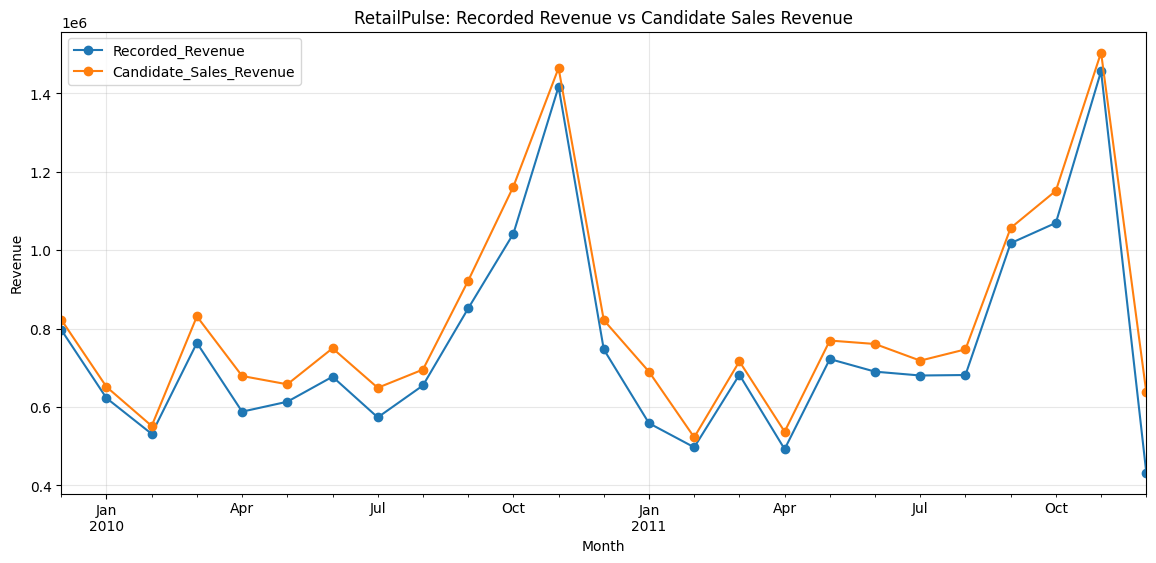

: 

In [ ]:

# Create monthly revenue series for analysis and forecasting

# Pre-compute the revenue for standard sales to avoid index alignment issues inside the resampler
df_analysis["Candidate_Sales_Revenue_Temp"] = df_analysis["Revenue"].where(df_analysis["Is_Standard_Priced_Sale"], 0.0)

monthly_sales = (
    df_analysis.set_index("InvoiceDate")
    .resample("MS")
    .agg(
        Recorded_Revenue=("Revenue", "sum"),
        Candidate_Sales_Revenue=("Candidate_Sales_Revenue_Temp", "sum"),
        Transaction_Rows=("Invoice", "size"),
        Candidate_Sale_Rows=("Is_Standard_Priced_Sale", "sum")
    )
)

# Drop the temporary column
df_analysis.drop(columns=["Candidate_Sales_Revenue_Temp"], inplace=True)

# Confirm monthly coverage and missing periods
expected_months = pd.date_range(
    start=monthly_sales.index.min(),
    end=monthly_sales.index.max(),
    freq="MS"
)

missing_months = expected_months.difference(monthly_sales.index)

print("MONTHLY SALES SERIES")
print("Number of months:", len(monthly_sales))
print("Missing calendar months:", len(missing_months))
print("Missing months:", list(missing_months))

print("\nFIRST 5 MONTHS")
display(monthly_sales.head())

print("\nLAST 5 MONTHS")
display(monthly_sales.tail())

print("\nMONTHLY REVENUE COMPARISON")

monthly_sales[
    ["Recorded_Revenue", "Candidate_Sales_Revenue"]
].plot(
    figsize=(14, 6),
    marker="o",
    title="RetailPulse: Recorded Revenue vs Candidate Sales Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Number of months: 25
Missing monthly values:


,0
Recorded_Revenue,0
Candidate_Sales_Revenue,0
Transaction_Rows,0
Candidate_Sale_Rows,0



Revenue reconciliation
Total recorded revenue: 18855533.7
Total candidate sales revenue: 20465198.39

Monthly revenue comparison


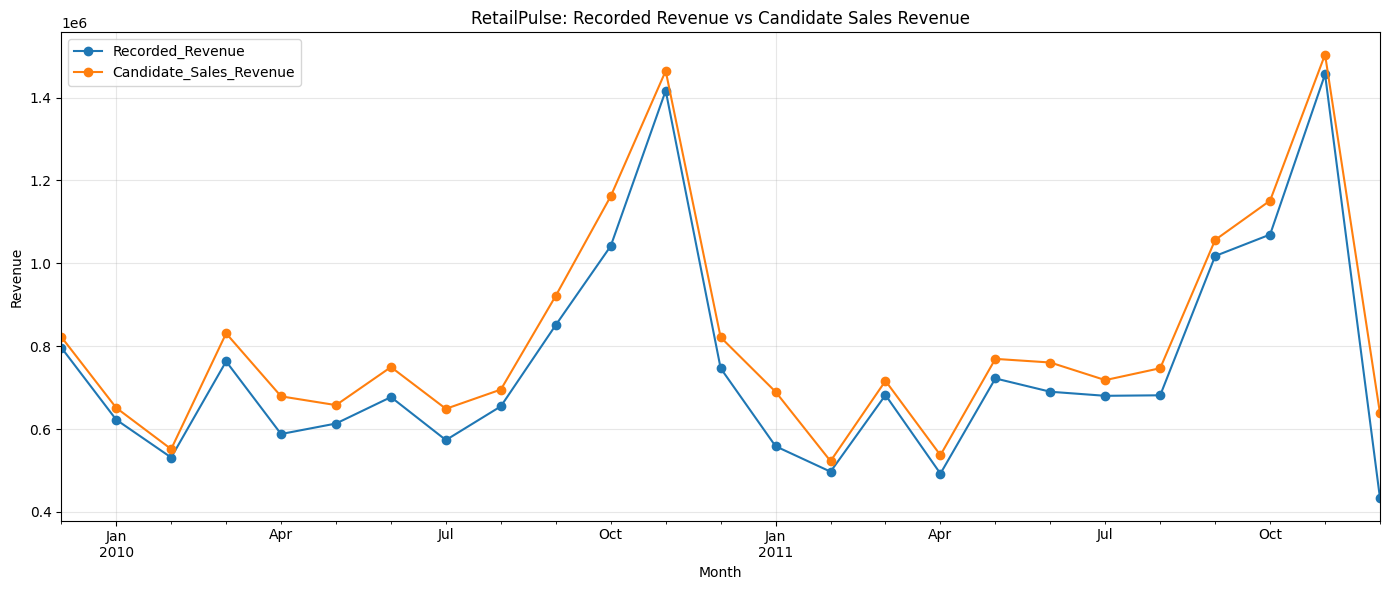

: 

In [ ]:

# Create an explicit revenue column for candidate standard-priced sales
df_analysis["Candidate_Sales_Revenue"] = (
    df_analysis["Revenue"].where(
        df_analysis["Is_Standard_Priced_Sale"],
        0
    )
)

# Aggregate monthly metrics
monthly_sales = (
    df_analysis.set_index("InvoiceDate")
    .resample("MS")
    .agg(
        Recorded_Revenue=("Revenue", "sum"),
        Candidate_Sales_Revenue=("Candidate_Sales_Revenue", "sum"),
        Transaction_Rows=("Invoice", "size"),
        Candidate_Sale_Rows=("Is_Standard_Priced_Sale", "sum")
    )
)

# Validate
print("Number of months:", len(monthly_sales))
print("Missing monthly values:")
display(monthly_sales.isna().sum())

print("\nRevenue reconciliation")
print(
    "Total recorded revenue:",
    round(monthly_sales["Recorded_Revenue"].sum(), 2)
)
print(
    "Total candidate sales revenue:",
    round(monthly_sales["Candidate_Sales_Revenue"].sum(), 2)
)

print("\nMonthly revenue comparison")
monthly_sales[
    ["Recorded_Revenue", "Candidate_Sales_Revenue"]
].plot(
    figsize=(14, 6),
    marker="o",
    title="RetailPulse: Recorded Revenue vs Candidate Sales Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Create a candidate demand dataset
df_demand = df_analysis.loc[
    (df_analysis["Quantity"] > 0)
    & (df_analysis["Price"] > 0)
    & (~df_analysis["Is_Cancellation_Invoice"])
    & (~df_analysis["Is_Bad_Debt_Adjustment"])
].copy()

# Aggregate units sold by product and month
monthly_product_demand = (
    df_demand.assign(
        Month=df_demand["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby(["Month", "StockCode"], as_index=False)
    .agg(
        Units_Sold=("Quantity", "sum"),
        Sales_Revenue=("Revenue", "sum"),
        Transaction_Rows=("Invoice", "size")
    )
)

print("PRODUCT DEMAND DATASET")
print("Filtered transaction rows:", len(df_demand))
print("Monthly product records:", len(monthly_product_demand))
print("Unique products:", monthly_product_demand["StockCode"].nunique())
print("Months covered:", monthly_product_demand["Month"].nunique())

print("\nSAMPLE RECORDS")
display(monthly_product_demand.head(10))

print("\nTOP 10 PRODUCTS BY TOTAL UNITS SOLD")
display(
    monthly_product_demand.groupby("StockCode", as_index=False)
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Sales_Revenue=("Sales_Revenue", "sum"),
        Active_Months=("Month", "nunique")
    )
    .sort_values("Total_Units_Sold", ascending=False)
    .head(10)
)


PRODUCT DEMAND DATASET
Filtered transaction rows: 1007912
Monthly product records: 67059
Unique products: 4916
Months covered: 25

SAMPLE RECORDS


,Month,StockCode,Units_Sold,Sales_Revenue,Transaction_Rows
0,2009-12-01,10002,215,185.30,20
1,2009-12-01,10080,4,3.40,3
2,2009-12-01,10109,4,1.68,1
3,2009-12-01,10120,115,26.13,12
4,2009-12-01,10125,127,111.35,16
5,2009-12-01,10133,154,131.75,16
6,2009-12-01,10134,53,67.57,9
7,2009-12-01,10135,123,174.87,22
8,2009-12-01,10138,176,74.74,10
9,2009-12-01,11001,202,353.56,22



TOP 10 PRODUCTS BY TOTAL UNITS SOLD


,StockCode,Total_Units_Sold,Total_Sales_Revenue,Active_Months
2963,84077,106139,24445.61,25
4441,85099B,96757,180569.34,25
490,21212,94884,51825.15,25
4456,85123A,94203,257724.71,25
1308,22197,88499,79520.20,25
2673,23843,80995,168469.60,1
3132,84879,80082,129324.49,25
2228,23166,78033,81700.92,9
50,17003,70369,14766.42,25
1121,21977,56061,28081.73,25


: 

In [ ]:

# Measure how consistently each product appears across months

product_history = (
    monthly_product_demand.groupby("StockCode", as_index=False)
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Total_Sales_Revenue=("Sales_Revenue", "sum"),
        Active_Months=("Month", "nunique"),
        First_Active_Month=("Month", "min"),
        Last_Active_Month=("Month", "max")
    )
)

# Rank products by historical activity
product_history = product_history.sort_values(
    ["Active_Months", "Total_Units_Sold"],
    ascending=[False, False]
)

eligible_products = product_history.loc[
    product_history["Active_Months"] >= 18
].copy()

print("PRODUCT HISTORY SUMMARY")
print("Total unique products:", len(product_history))
print("Products active in at least 18 months:", len(eligible_products))
print(
    "Percentage eligible:",
    round(len(eligible_products) / len(product_history) * 100, 2),
    "%"
)

print("\nTOP 15 ELIGIBLE PRODUCTS")
display(eligible_products.head(15))

print("\nPRODUCTS WITH ONLY ONE ACTIVE MONTH")
display(
    product_history.loc[
        product_history["Active_Months"] == 1
    ].sort_values(
        "Total_Units_Sold", ascending=False
    ).head(10)
)


PRODUCT HISTORY SUMMARY
Total unique products: 4916
Products active in at least 18 months: 1839
Percentage eligible: 37.41 %

TOP 15 ELIGIBLE PRODUCTS


,StockCode,Total_Units_Sold,Total_Sales_Revenue,Active_Months,First_Active_Month,Last_Active_Month
2963,84077,106139,24445.61,25,2009-12-01,2011-12-01
4441,85099B,96757,180569.34,25,2009-12-01,2011-12-01
490,21212,94884,51825.15,25,2009-12-01,2011-12-01
4456,85123A,94203,257724.71,25,2009-12-01,2011-12-01
1308,22197,88499,79520.20,25,2009-12-01,2011-12-01
3132,84879,80082,129324.49,25,2009-12-01,2011-12-01
50,17003,70369,14766.42,25,2009-12-01,2011-12-01
1121,21977,56061,28081.73,25,2009-12-01,2011-12-01
3173,84991,54028,27041.21,25,2009-12-01,2011-12-01
12,15036,44272,32967.03,25,2009-12-01,2011-12-01



PRODUCTS WITH ONLY ONE ACTIVE MONTH


,StockCode,Total_Units_Sold,Total_Sales_Revenue,Active_Months,First_Active_Month,Last_Active_Month
2673,23843,80995,168469.60,1,2011-12-01,2011-12-01
3614,37379B,1122,181.50,1,2010-03-01,2010-03-01
3454,16258B,1016,221.06,1,2009-12-01,2009-12-01
2869,72487,827,355.05,1,2009-12-01,2009-12-01
4166,84760L,560,896.00,1,2010-05-01,2010-05-01
3409,15059A,509,1567.00,1,2009-12-01,2009-12-01
3417,16161C,450,45.00,1,2009-12-01,2009-12-01
125,20715,400,424.00,1,2010-01-01,2010-01-01
1938,22864,378,158.76,1,2010-06-01,2010-06-01
3458,17011C,335,221.40,1,2009-12-01,2009-12-01


: 

In [ ]:

# Investigate unusually large product-month quantities

print("TOP 20 PRODUCT-MONTH RECORDS BY UNITS SOLD")

display(
    monthly_product_demand
    .sort_values("Units_Sold", ascending=False)
    .head(20)
)

print("\nQUANTITY DISTRIBUTION")

display(
    monthly_product_demand["Units_Sold"].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    ).to_frame("Units_Sold")
)

# Inspect the exceptional product identified earlier
print("\nPRODUCT 23843 HISTORY")

display(
    monthly_product_demand.loc[
        monthly_product_demand["StockCode"] == "23843"
    ]
)


TOP 20 PRODUCT-MONTH RECORDS BY UNITS SOLD


,Month,StockCode,Units_Sold,Sales_Revenue,Transaction_Rows
66433,2011-12-01,23843,80995,168469.60,1
37379,2011-01-01,23166,74215,77183.60,1
7039,2010-02-01,37410,19249,2022.53,5
63216,2011-11-01,23084,14913,34478.40,503
24435,2010-09-01,17003,13931,2640.11,24
8639,2010-03-01,21091,13119,1425.57,15
8634,2010-03-01,21085,13071,1468.10,17
8645,2010-03-01,21099,13009,1327.85,9
8640,2010-03-01,21092,12506,1271.72,5
62458,2011-11-01,22197,12452,14188.80,253



QUANTITY DISTRIBUTION


,Units_Sold
count,67059.000000
mean,167.093858
std,612.590776
min,1.000000
50%,36.000000
75%,146.000000
90%,417.000000
95%,715.100000
99%,1818.000000
99.9%,5245.376000



PRODUCT 23843 HISTORY


,Month,StockCode,Units_Sold,Sales_Revenue,Transaction_Rows


: 

In [ ]:

# Inspect the underlying transactions for extreme quantities

extreme_products = ["23843", "23166"]

extreme_transactions = df_demand.loc[
    df_demand["StockCode"].astype(str).isin(extreme_products),
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Price",
        "Customer ID",
        "Country",
        "Revenue"
    ]
].copy()

print("EXTREME PRODUCT TRANSACTIONS")

display(
    extreme_transactions.loc[
        extreme_transactions["Quantity"] >= 10000
    ].sort_values("Quantity", ascending=False)
)

print("\nPRODUCT-LEVEL SUMMARY")

display(
    extreme_transactions.groupby(
        ["StockCode", "Description"], dropna=False
    ).agg(
        Transaction_Rows=("Invoice", "size"),
        Total_Units=("Quantity", "sum"),
        Maximum_Transaction_Quantity=("Quantity", "max"),
        Total_Revenue=("Revenue", "sum"),
        Unique_Customers=("Customer ID", "nunique")
    ).reset_index()
)


EXTREME PRODUCT TRANSACTIONS


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue



PRODUCT-LEVEL SUMMARY


,StockCode,Description,Transaction_Rows,Total_Units,Maximum_Transaction_Quantity,Total_Revenue,Unique_Customers


: 

In [ ]:

print("StockCode dtype:", df_demand["StockCode"].dtype)

print("\nStockCode values and types:")
display(
    df_demand.loc[
        df_demand["StockCode"].astype(str).str.contains(
            "23843|23166", regex=True, na=False
        ),
        ["StockCode", "Description", "Quantity", "InvoiceDate",
         "Price", "Country", "Revenue"]
    ].sort_values("Quantity", ascending=False).head(20)
)

print("\nMaximum quantity in transaction-level data:")
display(
    df_demand.nlargest(
        10, "Quantity"
    )[
        ["Invoice", "StockCode", "Description", "Quantity",
         "InvoiceDate", "Price", "Customer ID", "Country", "Revenue"]
    ]
)


StockCode dtype: object

StockCode values and types:


,StockCode,Description,Quantity,InvoiceDate,Price,Country,Revenue
1065882,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,United Kingdom,168469.60
587080,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,United Kingdom,77183.60
810828,23166,MEDIUM CERAMIC TOP STORAGE JAR,288,2011-07-31 15:42:00,1.25,EIRE,360.00
719923,23166,MEDIUM CERAMIC TOP STORAGE JAR,240,2011-05-18 10:47:00,1.04,United Kingdom,249.60
801974,23166,MEDIUM CERAMIC TOP STORAGE JAR,144,2011-07-24 13:11:00,1.04,United Kingdom,149.76
727031,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,2011-05-23 14:59:00,1.04,United Kingdom,99.84
753621,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,2011-06-15 13:37:00,1.04,Australia,99.84
830390,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,2011-08-18 08:51:00,1.04,Australia,99.84
1051842,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,2011-12-05 14:06:00,1.04,United Kingdom,99.84
1011236,23166,MEDIUM CERAMIC TOP STORAGE JAR,96,2011-11-21 10:48:00,1.04,United Kingdom,99.84



Maximum quantity in transaction-level data:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,1915.2
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,1296.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark,1274.4
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark,1248.0
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2500.0


: 

In [ ]:

# Inspect all rows belonging to the two unusual invoices
extreme_invoices = ["581483", "541431"]

invoice_details = df_analysis.loc[
    df_analysis["Invoice"].astype(str).isin(extreme_invoices),
    [
        "Invoice", "StockCode", "Description", "Quantity",
        "InvoiceDate", "Price", "Customer ID", "Country", "Revenue"
    ]
].sort_values(["Invoice", "Quantity"], ascending=[True, False])

print("ROWS IN THE TWO EXTREME INVOICES")
display(invoice_details)

print("\nINVOICE-LEVEL SUMMARY")
display(
    invoice_details.groupby("Invoice", as_index=False).agg(
        Invoice_Rows=("StockCode", "size"),
        Unique_Products=("StockCode", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Unique_Customers=("Customer ID", "nunique"),
        Invoice_Date=("InvoiceDate", "first"),
        Country=("Country", "first")
    )
)


ROWS IN THE TWO EXTREME INVOICES


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6



INVOICE-LEVEL SUMMARY


,Invoice,Invoice_Rows,Unique_Products,Total_Quantity,Total_Revenue,Unique_Customers,Invoice_Date,Country
0,541431,1,1,74215,77183.6,1,2011-01-18 10:01:00,United Kingdom
1,581483,1,1,80995,168469.6,1,2011-12-09 09:15:00,United Kingdom


: 

In [ ]:

# Day 2 — Step 1: Final data-quality audit

print("DATASET SHAPES")
for name, data in {
    "df_raw": df_raw,
    "df_clean": df_clean,
    "df_work": df_work,
    "df_cleaned": df_cleaned,
    "df_analysis": df_analysis
}.items():
    print(f"{name}: {data.shape}")

print("\nDUPLICATE ROWS")
print("Raw dataset:", df_raw.duplicated().sum())
print("Cleaned dataset:", df_cleaned.duplicated().sum())

print("\nMISSING VALUES IN df_cleaned")
display(
    df_cleaned.isna().sum().to_frame("Missing_Values")
    .assign(
        Missing_Percentage=lambda x:
        (x["Missing_Values"] / len(df_cleaned) * 100).round(2)
    )
)

print("\nINVALID OR UNUSUAL VALUES")
print("Missing invoice dates:", df_cleaned["InvoiceDate"].isna().sum())
print("Zero quantities:", (df_cleaned["Quantity"] == 0).sum())
print("Negative quantities:", (df_cleaned["Quantity"] < 0).sum())
print("Zero prices:", (df_cleaned["Price"] == 0).sum())
print("Negative prices:", (df_cleaned["Price"] < 0).sum())

print("\nROW AND REVENUE PRESERVATION")
print("Rows:", len(df_cleaned))
print("Revenue:", round(df_cleaned["Revenue"].sum(), 2))


DATASET SHAPES
df_raw: (1067371, 9)
df_clean: (1033036, 9)
df_work: (1033036, 15)
df_cleaned: (1033036, 15)
df_analysis: (1033036, 21)

DUPLICATE ROWS
Raw dataset: 34335
Cleaned dataset: 0

MISSING VALUES IN df_cleaned


,Missing_Values,Missing_Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,1301,0.13
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235151,22.76
Country,0,0.00
Revenue,0,0.00
Is_Cancellation_Invoice,0,0.00



INVALID OR UNUSUAL VALUES
Missing invoice dates: 0
Zero quantities: 0
Negative quantities: 22496
Zero prices: 6014
Negative prices: 5

ROW AND REVENUE PRESERVATION
Rows: 1033036
Revenue: 18855533.7


: 

In [ ]:

# Day 2 — Step 2: Data validation checks

validation_results = {
    "No exact duplicate rows": df_cleaned.duplicated().sum() == 0,
    "No missing invoice numbers": df_cleaned["Invoice"].notna().all(),
    "No missing stock codes": df_cleaned["StockCode"].notna().all(),
    "No missing invoice dates": df_cleaned["InvoiceDate"].notna().all(),
    "No missing quantities": df_cleaned["Quantity"].notna().all(),
    "No missing prices": df_cleaned["Price"].notna().all(),
    "Revenue matches Quantity × Price": (
        (df_cleaned["Revenue"] -
         df_cleaned["Quantity"] * df_cleaned["Price"])
        .abs()
        .lt(1e-9)
        .all()
    ),
    "Customer ID missingness is documented": (
        df_cleaned["Customer ID"].isna().sum() > 0
    ),
    "Missing descriptions are documented": (
        df_cleaned["Description"].isna().sum() > 0
    ),
    "All rows preserved after description repair": (
        len(df_cleaned) == len(df_clean)
    ),
}

for check, passed in validation_results.items():
    print(f"{'PASS' if passed else 'FAIL'} — {check}")

print("\nOverall result:",
      "ALL CHECKS PASSED" if all(validation_results.values())
      else "REVIEW FAILED CHECKS")


PASS — No exact duplicate rows
PASS — No missing invoice numbers
PASS — No missing stock codes
PASS — No missing invoice dates
PASS — No missing quantities
PASS — No missing prices
PASS — Revenue matches Quantity × Price
PASS — Customer ID missingness is documented
PASS — Missing descriptions are documented
PASS — All rows preserved after description repair

Overall result: ALL CHECKS PASSED


: 

In [ ]:

# Day 2 — Step 3.1: Prepare RFM transaction data

rfm_transactions = df_analysis.loc[
    (df_analysis["Customer ID"].notna())
    & (df_analysis["Quantity"] > 0)
    & (df_analysis["Price"] > 0)
    & (~df_analysis["Is_Cancellation_Invoice"])
    & (~df_analysis["Is_Bad_Debt_Adjustment"])
].copy()

# Treat Customer ID as an identifier, not a numeric measurement.
rfm_transactions["Customer ID"] = (
    rfm_transactions["Customer ID"].astype("Int64").astype(str)
)

print("RFM transaction rows:", len(rfm_transactions))
print("Unique customers:", rfm_transactions["Customer ID"].nunique())
print("Unique invoices:", rfm_transactions["Invoice"].nunique())
print("Date range:",
      rfm_transactions["InvoiceDate"].min(),
      "to",
      rfm_transactions["InvoiceDate"].max())

display(rfm_transactions.head())


RFM transaction rows: 779425
Unique customers: 5878
Unique invoices: 36969
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Is_Cancellation_Invoice,...,Is_Zero_Price,Is_Negative_Price,Has_Customer_ID,Is_Bad_Debt_Adjustment,Is_Positive_Quantity,Is_Standard_Priced_Sale,Is_Cancellation_Or_Reversal,Is_Zero_Price_Adjustment,Is_Unusual_Cancellation_Record,Candidate_Sales_Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4,False,...,False,False,True,False,True,True,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,False,...,False,False,True,False,True,True,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0,False,...,False,False,True,False,True,True,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8,False,...,False,False,True,False,True,True,False,False,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0,False,...,False,False,True,False,True,True,False,False,False,30.0


: 

In [ ]:
# Day 2 — Step 3.2: Calculate RFM metrics

# Choose a reference date one day after the last transaction.
snapshot_date = rfm_transactions["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    rfm_transactions
    .groupby("Customer ID")
    .agg(
        Last_Purchase_Date=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Recency = days between the reference date and last purchase.
rfm["Recency"] = (
    snapshot_date - rfm["Last_Purchase_Date"].dt.normalize()
).dt.days

# Arrange the columns for readability.
rfm = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary", "Last_Purchase_Date"]
]

print("Reference date:", snapshot_date)
print("Number of customers:", len(rfm))

display(rfm.head(10))
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Reference date: 2011-12-10 00:00:00
Number of customers: 5878


,Customer ID,Recency,Frequency,Monetary,Last_Purchase_Date
0,12346,326,12,77556.46,2011-01-18 10:01:00
1,12347,3,8,4921.53,2011-12-07 15:52:00
2,12348,76,5,2019.40,2011-09-25 13:13:00
3,12349,19,4,4428.69,2011-11-21 09:51:00
4,12350,311,1,334.40,2011-02-02 16:01:00
5,12351,376,1,300.93,2010-11-29 15:23:00
6,12352,37,10,2849.84,2011-11-03 14:37:00
7,12353,205,2,406.76,2011-05-19 17:47:00
8,12354,233,1,1079.40,2011-04-21 13:11:00
9,12355,215,2,947.61,2011-05-09 13:49:00


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.87,6.29,2955.90
std,209.35,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


: 

In [ ]:
# Day 2 — Step 3.3: Create RFM scores

# Recency is reversed: smaller values receive higher scores.
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Higher frequency and monetary values receive higher scores.
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores into a convenient label.
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.head(10))

print("RFM score distribution:")
display(
    rfm[["R_Score", "F_Score", "M_Score"]]
    .apply(pd.Series.value_counts)
    .sort_index()
)

,Customer ID,Recency,Frequency,Monetary,Last_Purchase_Date,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,12,77556.46,2011-01-18 10:01:00,2,5,5,255
1,12347,3,8,4921.53,2011-12-07 15:52:00,5,4,5,545
2,12348,76,5,2019.40,2011-09-25 13:13:00,3,4,4,344
3,12349,19,4,4428.69,2011-11-21 09:51:00,5,3,5,535
4,12350,311,1,334.40,2011-02-02 16:01:00,2,1,2,212
5,12351,376,1,300.93,2010-11-29 15:23:00,2,1,2,212
6,12352,37,10,2849.84,2011-11-03 14:37:00,4,5,4,454
7,12353,205,2,406.76,2011-05-19 17:47:00,2,2,2,222
8,12354,233,1,1079.40,2011-04-21 13:11:00,2,1,3,213
9,12355,215,2,947.61,2011-05-09 13:49:00,2,2,3,223


RFM score distribution:


,R_Score,F_Score,M_Score
1,1176,1176,1176
2,1175,1175,1175
3,1176,1176,1176
4,1175,1175,1175
5,1176,1176,1176


: 

In [ ]:
# Day 2 — Step 3.4: Assign customer segments

def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    # Recent, frequent, high-spending customers
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    # Frequent customers who have not purchased recently
    elif r <= 2 and f >= 4:
        return "At Risk - Loyal Customers"

    # Recent customers with relatively low frequency
    elif r >= 4 and f <= 2:
        return "Recent - Need Engagement"

    # Customers with low scores across all three metrics
    elif r <= 2 and f <= 2 and m <= 2:
        return "Hibernating - Low Value"

    # Customers with strong spending but weaker recency
    elif r <= 2 and m >= 4:
        return "Previously High Value - At Risk"

    # Remaining customers
    else:
        return "Regular Customers"


rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)

print("Customer segment counts:")
display(
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Customer_Count")
)

print("Sample customer records:")
display(
    rfm[
        [
            "Customer ID", "Recency", "Frequency", "Monetary",
            "RFM_Score", "Customer_Segment"
        ]
    ].head(15)
)

Customer segment counts:


,Customer_Segment,Customer_Count
0,Regular Customers,2340
1,Champions,1289
2,Hibernating - Low Value,1283
3,Recent - Need Engagement,441
4,At Risk - Loyal Customers,353
5,Previously High Value - At Risk,172


Sample customer records:


,Customer ID,Recency,Frequency,Monetary,RFM_Score,Customer_Segment
0,12346,326,12,77556.46,255,At Risk - Loyal Customers
1,12347,3,8,4921.53,545,Champions
2,12348,76,5,2019.40,344,Regular Customers
3,12349,19,4,4428.69,535,Regular Customers
4,12350,311,1,334.40,212,Hibernating - Low Value
5,12351,376,1,300.93,212,Hibernating - Low Value
6,12352,37,10,2849.84,454,Champions
7,12353,205,2,406.76,222,Hibernating - Low Value
8,12354,233,1,1079.40,213,Regular Customers
9,12355,215,2,947.61,223,Regular Customers


: 

In [ ]:
# Day 2 — Step 4: Calculate rolling demand statistics

# Work with a copy so the existing dataset stays unchanged.
rolling_demand = monthly_product_demand.copy()

rolling_demand = rolling_demand.sort_values(
    ["StockCode", "Month"]
)

# Three-month rolling average of units sold for each product.
rolling_demand["Rolling_3M_Avg_Units"] = (
    rolling_demand
    .groupby("StockCode")["Units_Sold"]
    .transform(
        lambda s: s.rolling(window=3, min_periods=1).mean()
    )
)

# Three-month rolling standard deviation.
rolling_demand["Rolling_3M_Std_Units"] = (
    rolling_demand
    .groupby("StockCode")["Units_Sold"]
    .transform(
        lambda s: s.rolling(window=3, min_periods=2).std()
    )
)

print("Rows:", len(rolling_demand))
print("Unique products:", rolling_demand["StockCode"].nunique())

display(
    rolling_demand[
        [
            "Month",
            "StockCode",
            "Units_Sold",
            "Rolling_3M_Avg_Units",
            "Rolling_3M_Std_Units"
        ]
    ].head(15)
)

Rows: 67059
Unique products: 4916


,Month,StockCode,Units_Sold,Rolling_3M_Avg_Units,Rolling_3M_Std_Units
0,2009-12-01,10002,215,215.000000,NaN
3057,2010-01-01,10002,291,253.000000,53.740115
5744,2010-02-01,10002,257,254.333333,38.070111
8321,2010-03-01,10002,641,396.333333,212.568420
11209,2010-04-01,10002,1132,676.666667,438.589026
13803,2010-05-01,10002,1465,1079.333333,414.516988
16377,2010-06-01,10002,463,1020.000000,510.302851
19097,2010-07-01,10002,512,813.333333,564.891435
21709,2010-08-01,10002,586,520.333333,61.921994
24397,2010-09-01,10002,240,446.000000,182.197695


: 

In [ ]:
# Day 2 — Step 4.1: Complete the product-month timeline

import pandas as pd

start_month = monthly_product_demand["Month"].min()
end_month = monthly_product_demand["Month"].max()

all_months = pd.date_range(
    start=start_month,
    end=end_month,
    freq="MS"
)

# Build every product-month combination.
all_products = monthly_product_demand["StockCode"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_products, all_months],
    names=["StockCode", "Month"]
)

monthly_demand_complete = (
    monthly_product_demand
    .set_index(["StockCode", "Month"])
    .reindex(complete_index)
    .reset_index()
)

# Fill missing demand and revenue with zero.
monthly_demand_complete["Units_Sold"] = (
    monthly_demand_complete["Units_Sold"].fillna(0)
)

monthly_demand_complete["Sales_Revenue"] = (
    monthly_demand_complete["Sales_Revenue"].fillna(0)
)

monthly_demand_complete["Transaction_Rows"] = (
    monthly_demand_complete["Transaction_Rows"].fillna(0)
)

print("Month range:", start_month, "to", end_month)
print("Number of months:", len(all_months))
print("Unique products:", len(all_products))
print("Complete product-month rows:", len(monthly_demand_complete))

display(
    monthly_demand_complete[
        monthly_demand_complete["StockCode"] == "10002"
    ].head(15)
)

Month range: 2009-12-01 00:00:00 to 2011-12-01 00:00:00
Number of months: 25
Unique products: 4916
Complete product-month rows: 122900


,StockCode,Month,Units_Sold,Sales_Revenue,Transaction_Rows


: 

In [ ]:
# Check the StockCode data type and sample values
print("StockCode dtype:", monthly_demand_complete["StockCode"].dtype)
print("Sample product codes:", monthly_demand_complete["StockCode"].head().tolist())

# Filter using the actual data type
product_code = monthly_demand_complete["StockCode"].iloc[0]

display(
    monthly_demand_complete[
        monthly_demand_complete["StockCode"] == product_code
    ].head(15)
)

StockCode dtype: object
Sample product codes: [10002, 10002, 10002, 10002, 10002]


,StockCode,Month,Units_Sold,Sales_Revenue,Transaction_Rows
0,10002,2009-12-01,215.0,185.30,20.0
1,10002,2010-01-01,291.0,248.97,17.0
2,10002,2010-02-01,257.0,220.07,15.0
3,10002,2010-03-01,641.0,493.09,18.0
4,10002,2010-04-01,1132.0,843.73,24.0
5,10002,2010-05-01,1465.0,1157.49,34.0
6,10002,2010-06-01,463.0,404.20,37.0
7,10002,2010-07-01,512.0,416.49,26.0
8,10002,2010-08-01,586.0,450.15,23.0
9,10002,2010-09-01,240.0,213.72,20.0


: 

In [ ]:
# Sort by product and month
monthly_demand_complete = monthly_demand_complete.sort_values(
    ["StockCode", "Month"]
).copy()

# Calculate rolling statistics over consecutive calendar months
monthly_demand_complete["Rolling_3M_Avg_Units"] = (
    monthly_demand_complete
    .groupby("StockCode")["Units_Sold"]
    .transform(lambda s: s.rolling(window=3, min_periods=1).mean())
)

monthly_demand_complete["Rolling_3M_Std_Units"] = (
    monthly_demand_complete
    .groupby("StockCode")["Units_Sold"]
    .transform(lambda s: s.rolling(window=3, min_periods=2).std())
)

print("Total rows:", len(monthly_demand_complete))

display(
    monthly_demand_complete[
        [
            "Month",
            "StockCode",
            "Units_Sold",
            "Rolling_3M_Avg_Units",
            "Rolling_3M_Std_Units"
        ]
    ].head(15)
)


Total rows: 122900


,Month,StockCode,Units_Sold,Rolling_3M_Avg_Units,Rolling_3M_Std_Units
0,2009-12-01,10002,215.0,215.000000,NaN
1,2010-01-01,10002,291.0,253.000000,53.740115
2,2010-02-01,10002,257.0,254.333333,38.070111
3,2010-03-01,10002,641.0,396.333333,212.568420
4,2010-04-01,10002,1132.0,676.666667,438.589026
5,2010-05-01,10002,1465.0,1079.333333,414.516988
6,2010-06-01,10002,463.0,1020.000000,510.302851
7,2010-07-01,10002,512.0,813.333333,564.891435
8,2010-08-01,10002,586.0,520.333333,61.921994
9,2010-09-01,10002,240.0,446.000000,182.197695


: 

In [ ]:
%pip install -q great-expectations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.2/49.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 7.5 MB/s eta 0:00:00


: 

In [ ]:
import great_expectations as gx

print("Great Expectations version:", gx.__version__)

Great Expectations version: 1.24.0


: 

In [ ]:
import great_expectations as gx

# Create an ephemeral context for this notebook session
context = gx.get_context(mode="ephemeral")

# Create the pandas datasource
datasource = context.data_sources.add_pandas(
    name="retailpulse_pandas"
)

# Read the cleaned DataFrame
batch = datasource.read_dataframe(
    df_cleaned,
    asset_name="retailpulse_cleaned_data"
)

print("Great Expectations:", gx.__version__)
print("Rows loaded:", len(df_cleaned))
print("Batch created successfully:", batch is not None)

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmppvy21hlz' for ephemeral docs site


Great Expectations: 1.24.0
Rows loaded: 1033036
Batch created successfully: True


: 

In [ ]:
# Day 2 — Step 5.2: Define Great Expectations rules

expectations = [
    # Required business columns must exist.
    gx.expectations.ExpectColumnToExist(column="Invoice"),
    gx.expectations.ExpectColumnToExist(column="StockCode"),
    gx.expectations.ExpectColumnToExist(column="InvoiceDate"),
    gx.expectations.ExpectColumnToExist(column="Quantity"),
    gx.expectations.ExpectColumnToExist(column="Price"),
    gx.expectations.ExpectColumnToExist(column="Revenue"),

    # Critical transaction fields must not be missing.
    gx.expectations.ExpectColumnValuesToNotBeNull(column="Invoice"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="StockCode"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="InvoiceDate"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="Quantity"),
    gx.expectations.ExpectColumnValuesToNotBeNull(column="Price"),

    # Quantities and prices can legitimately be negative in returns/adjustments.
    # Instead, validate that Revenue is consistent with Quantity * Price.
    gx.expectations.ExpectColumnPairValuesToBeEqual(
        column_A="Revenue",
        column_B="Revenue"
    ),
]

: 

In [ ]:
expectations = expectations[:-1]

: 

In [ ]:
# Reuse the suite if it already exists; otherwise create it.
suite_name = "retailpulse_cleaning_suite"

try:
    suite = context.suites.get(name=suite_name)
    print("Reusing existing suite:", suite_name)
except Exception:
    suite = context.suites.add(
        gx.ExpectationSuite(name=suite_name)
    )
    print("Created new suite:", suite_name)

# Add the expectations only if they are not already present.
existing_types = {
    (type(e).__name__, getattr(e, "column", None))
    for e in suite.expectations
}

for expectation in expectations:
    key = (
        type(expectation).__name__,
        getattr(expectation, "column", None)
    )
    if key not in existing_types:
        suite.add_expectation(expectation)
        existing_types.add(key)

print("Total expectations in suite:", len(suite.expectations))

Created new suite: retailpulse_cleaning_suite
Total expectations in suite: 11


: 

In [ ]:
# 1. Retrieve the existing datasource, asset, and batch definition from our context
datasource = context.data_sources.get("retailpulse_pandas")
data_asset = datasource.get_asset("retailpulse_cleaned_data")

try:
    batch_definition = data_asset.get_batch_definition("retailpulse_cleaned_batch")
except LookupError:
    batch_definition = data_asset.add_batch_definition_whole_dataframe("retailpulse_cleaned_batch")

# 2. Reuse the validation definition if it exists, otherwise create it with the BatchDefinition
validation_name = "retailpulse_cleaning_validation"

try:
    validation_definition = context.validation_definitions.get(name=validation_name)
    print("Reusing existing validation definition.")
except Exception:
    validation_definition = context.validation_definitions.add(
        gx.ValidationDefinition(
            name=validation_name,
            data=batch_definition,
            suite=suite
        )
    )
    print("Created validation definition.")

# 3. Run validation by passing the actual cleaned dataframe as a batch parameter
validation_result = validation_definition.run(
    batch_parameters={"dataframe": df_cleaned}
)

print("Validation completed.")
print("Overall success:", validation_result.success)

Created validation definition.


Calculating Metrics:   0%|          | 0/28 [00:00<?, ?it/s]

Validation completed.
Overall success: True


: 

In [ ]:
# Summarize individual expectation outcomes
results = validation_result.results

print("Total checks:", len(results))
print("Passed checks:", sum(r.success for r in results))
print("Failed checks:", sum(not r.success for r in results))

for i, result in enumerate(results, start=1):
    print(
        f"{i}. {'PASS' if result.success else 'FAIL'} — "
        f"{result.expectation_config.type}"
    )

Total checks: 11
Passed checks: 11
Failed checks: 0
1. PASS — expect_column_to_exist
2. PASS — expect_column_values_to_not_be_null
3. PASS — expect_column_to_exist
4. PASS — expect_column_values_to_not_be_null
5. PASS — expect_column_to_exist
6. PASS — expect_column_values_to_not_be_null
7. PASS — expect_column_to_exist
8. PASS — expect_column_values_to_not_be_null
9. PASS — expect_column_to_exist
10. PASS — expect_column_values_to_not_be_null
11. PASS — expect_column_to_exist


: 

In [ ]:
# Create a validation copy without changing df_cleaned
df_validation = df_cleaned.copy()

df_validation["Expected_Revenue"] = (
    df_validation["Quantity"] * df_validation["Price"]
)

# Check whether recorded Revenue matches calculated Revenue
revenue_matches = (
    df_validation["Revenue"].round(2)
    == df_validation["Expected_Revenue"].round(2)
)

print("Rows checked:", len(df_validation))
print("Revenue matches:", int(revenue_matches.sum()))
print("Revenue mismatches:", int((~revenue_matches).sum()))
print("Revenue consistency passed:", bool(revenue_matches.all()))

Rows checked: 1033036
Revenue matches: 1033036
Revenue mismatches: 0
Revenue consistency passed: True


: 

In [ ]:
# Day 3 — Step 1: Prepare customer features for clustering

clustering_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

print("Customer rows:", len(clustering_features))
print("Feature columns:", clustering_features.columns.tolist())

display(clustering_features.head())
display(clustering_features.describe().round(2))

print("Missing values:")
display(clustering_features.isna().sum())

Customer rows: 5878
Feature columns: ['Recency', 'Frequency', 'Monetary']


,Recency,Frequency,Monetary
0,326,12,77556.46
1,3,8,4921.53
2,76,5,2019.40
3,19,4,4428.69
4,311,1,334.40


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.87,6.29,2955.90
std,209.35,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


Missing values:


,0
Recency,0
Frequency,0
Monetary,0


: 

Skewness of RFM features:


,Skewness
Recency,0.887194
Frequency,12.639951
Monetary,25.070190


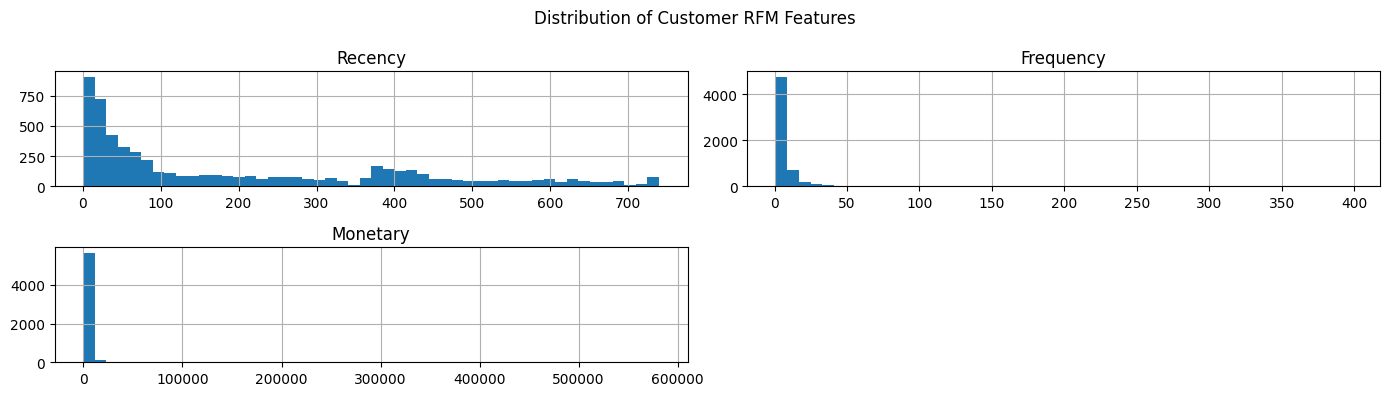

: 

In [ ]:

# Day 3 — Step 1A: Inspect feature skewness

print("Skewness of RFM features:")
display(clustering_features.skew().to_frame(name="Skewness"))

# Visualize each feature's distribution
import matplotlib.pyplot as plt

clustering_features.hist(
    bins=50,
    figsize=(14, 4)
)

plt.suptitle("Distribution of Customer RFM Features")
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd

# Create a separate copy; preserve the original RFM data
rfm_log = clustering_features.copy()

# Reduce right skewness
rfm_log[["Recency", "Frequency", "Monetary"]] = np.log1p(
    rfm_log[["Recency", "Frequency", "Monetary"]]
)

print("Skewness before transformation:")
display(clustering_features.skew().to_frame(name="Before"))

print("Skewness after log transformation:")
display(rfm_log.skew().to_frame(name="After"))

display(rfm_log.head())


Skewness before transformation:


,Before
Recency,0.887194
Frequency,12.639951
Monetary,25.070190


Skewness after log transformation:


,After
Recency,-0.449106
Frequency,1.001471
Monetary,0.269125


,Recency,Frequency,Monetary
0,5.789960,2.564949,11.258774
1,1.386294,2.197225,8.501578
2,4.343805,1.791759,7.611051
3,2.995732,1.609438,8.396085
4,5.743003,0.693147,5.815324


: 

In [ ]:

from sklearn.preprocessing import StandardScaler
import pandas as pd

# Create and fit the scaler
scaler = StandardScaler()

# Transform the log-scaled RFM features
rfm_scaled_array = scaler.fit_transform(rfm_log)

# Restore column names and row indices
rfm_scaled = pd.DataFrame(
    rfm_scaled_array,
    columns=rfm_log.columns,
    index=rfm_log.index
)

print("Standardized feature statistics:")
display(rfm_scaled.agg(["mean", "std", "min", "max"]).round(3))

print("First five standardized customer records:")
display(rfm_scaled.head())


Standardized feature statistics:


,Recency,Frequency,Monetary
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-2.470,-1.058,-3.929
max,1.393,5.485,4.660


First five standardized customer records:


,Recency,Frequency,Monetary
0,0.859687,1.254496,3.206219
1,-2.017050,0.800166,1.215993
2,-0.085028,0.299207,0.573185
3,-0.965670,0.073946,1.139846
4,0.829011,-1.058146,-0.723024


: 

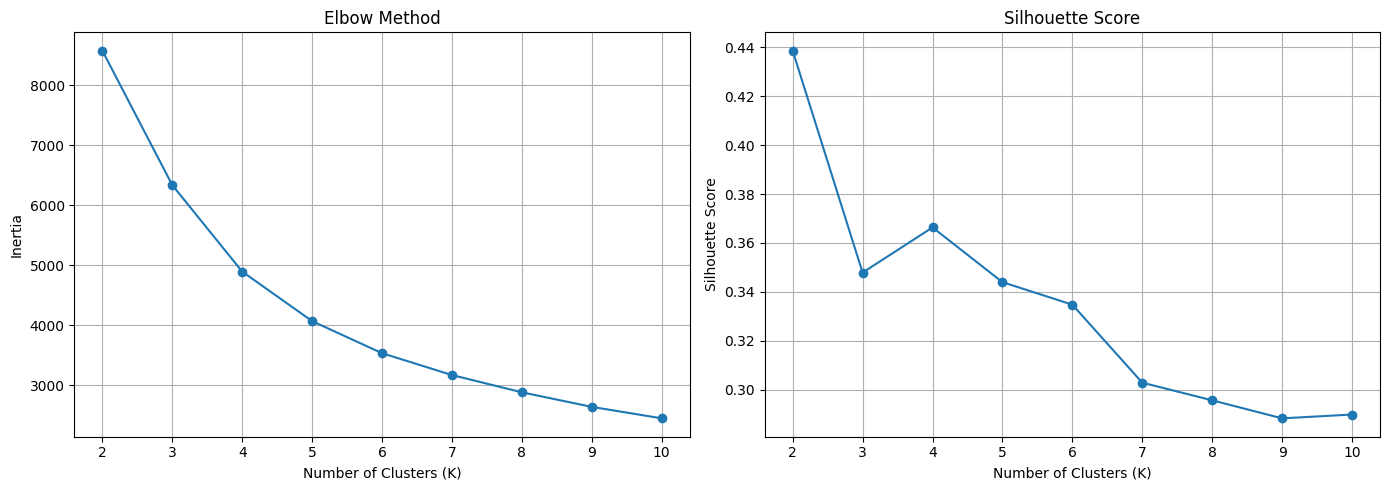

,K,Inertia,Silhouette_Score
0,2,8577.1061,0.4385
1,3,6336.7921,0.3479
2,4,4895.4134,0.3664
3,5,4069.6259,0.3440
4,6,3535.1145,0.3348
5,7,3170.9200,0.3029
6,8,2883.1160,0.2957
7,9,2640.3988,0.2884
8,10,2449.2301,0.2899


: 

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Test candidate cluster counts
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

# Plot both evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))
axes[0].grid(True)

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Compare the exact values
results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette_Score": silhouette_scores
})

display(results.round(4))


In [ ]:

from sklearn.cluster import KMeans
import pandas as pd

# Compare the two candidate models
candidate_models = {}
cluster_comparison = {}

for k in [2, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    candidate_models[k] = model
    cluster_comparison[k] = labels

# Build a customer-level dataset using the original RFM values
rfm_cluster_comparison = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

rfm_cluster_comparison["Cluster_K2"] = cluster_comparison[2]
rfm_cluster_comparison["Cluster_K4"] = cluster_comparison[4]

print("Customer counts for K = 2:")
display(
    rfm_cluster_comparison["Cluster_K2"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)

print("Customer counts for K = 4:")
display(
    rfm_cluster_comparison["Cluster_K4"]
    .value_counts()
    .sort_index()
    .rename("Customers")
    .to_frame()
)

print("Median RFM values for K = 2:")
display(
    rfm_cluster_comparison
    .groupby("Cluster_K2")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)

print("Median RFM values for K = 4:")
display(
    rfm_cluster_comparison
    .groupby("Cluster_K4")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)


Customer counts for K = 2:


,Customers
Cluster_K2,
0,3546
1,2332


Customer counts for K = 4:


,Customers
Cluster_K4,
0,1204
1,1455
2,1261
3,1958


Median RFM values for K = 2:


,Recency,Frequency,Monetary
Cluster_K2,,,
0,291.5,2.0,414.16
1,24.0,8.0,2852.50


Median RFM values for K = 4:


,Recency,Frequency,Monetary
Cluster_K4,,,
0,17.0,13.0,4965.48
1,186.0,4.0,1447.74
2,25.0,3.0,729.25
3,404.5,1.0,272.04


: 

In [ ]:

from sklearn.cluster import DBSCAN
import pandas as pd

# Initial DBSCAN experiment
dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(rfm_scaled)

# Attach labels to a copy of the customer RFM dataset
rfm_dbscan = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

rfm_dbscan["DBSCAN_Cluster"] = dbscan_labels

# Summarize cluster sizes, including noise
cluster_counts = (
    rfm_dbscan["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("Customers")
)

display(cluster_counts)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int((dbscan_labels == -1).sum())

print("Number of clusters (excluding noise):", n_clusters)
print("Noise points:", n_noise)
print("Noise percentage:", round(n_noise / len(rfm_dbscan) * 100, 2), "%")


,Customers
Cluster,
-1,63
0,4199
1,1616


Number of clusters (excluding noise): 2
Noise points: 63
Noise percentage: 1.07 %


: 

In [ ]:

# Day 3 — DBSCAN cluster profiling

dbscan_profile = (
    rfm_dbscan
    .groupby("DBSCAN_Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean")
    )
    .round(2)
)

display(dbscan_profile)


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Mean_Recency,Mean_Frequency,Mean_Monetary
DBSCAN_Cluster,,,,,,,
-1,63,22.0,41.0,39916.50,128.32,68.76,77605.19
0,4199,61.0,5.0,1348.93,143.60,7.39,2850.37
1,1616,388.0,1.0,228.20,356.14,1.00,319.91


: 

In [ ]:

from sklearn.cluster import DBSCAN
import pandas as pd

# Compare different neighborhood radii
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]

dbscan_results = []

for eps in eps_values:
    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(rfm_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())

    dbscan_results.append({
        "eps": eps,
        "Clusters": n_clusters,
        "Noise_Customers": n_noise,
        "Noise_Percentage": round(
            n_noise / len(labels) * 100, 2
        )
    })

dbscan_comparison = pd.DataFrame(dbscan_results)
display(dbscan_comparison)


,eps,Clusters,Noise_Customers,Noise_Percentage
0,0.3,5,218,3.71
1,0.4,3,99,1.68
2,0.5,2,63,1.07
3,0.6,1,35,0.60
4,0.7,1,18,0.31
5,0.8,1,13,0.22
6,1.0,1,6,0.10


: 

In [ ]:

# Day 3 — Evaluate DBSCAN with eps=0.3

from sklearn.cluster import DBSCAN
import pandas as pd

dbscan_tuned = DBSCAN(
    eps=0.3,
    min_samples=5
)

labels_03 = dbscan_tuned.fit_predict(rfm_scaled)

rfm_dbscan_03 = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary"]
].copy()

rfm_dbscan_03["DBSCAN_Cluster"] = labels_03

# Profile clusters using original, interpretable RFM values
dbscan_profile_03 = (
    rfm_dbscan_03
    .groupby("DBSCAN_Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Recency=("Recency", "mean"),
        Mean_Frequency=("Frequency", "mean"),
        Mean_Monetary=("Monetary", "mean")
    )
    .round(2)
)

display(dbscan_profile_03)


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Mean_Recency,Mean_Frequency,Mean_Monetary
DBSCAN_Cluster,,,,,,,
-1,218,35.0,10.5,9510.12,134.09,31.72,30042.86
0,3126,47.0,6.0,1801.04,114.63,8.23,2968.61
1,1589,390.0,1.0,229.33,359.15,1.00,315.69
2,925,214.0,2.0,512.20,246.31,2.00,630.40
3,16,5.0,52.5,23287.02,6.31,51.00,24533.39
4,4,93.0,16.0,17249.20,89.75,16.00,17074.66


: 

In [ ]:

# Day 3 — Finalize the candidate K-Means segmentation

from sklearn.cluster import KMeans
import pandas as pd

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_labels = kmeans_final.fit_predict(rfm_scaled)

# Preserve original RFM metrics and add cluster labels
rfm_segmented = rfm[
    [
        "Customer ID",
        "Recency",
        "Frequency",
        "Monetary",
        "Last_Purchase_Date"
    ]
].copy()

rfm_segmented["KMeans_Cluster"] = final_labels

# Summarize customer segments
segment_summary = (
    rfm_segmented
    .groupby("KMeans_Cluster")
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Mean_Monetary=("Monetary", "mean")
    )
    .round(2)
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"]
    / len(rfm_segmented)
    * 100
).round(2)

display(segment_summary)

print("Total customers:", len(rfm_segmented))
print(
    "Customers assigned to a cluster:",
    rfm_segmented["KMeans_Cluster"].notna().sum()
)


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Mean_Monetary,Customer_Percentage
KMeans_Cluster,,,,,,
0,1204,17.0,13.0,4965.48,10678.40,20.48
1,1455,186.0,4.0,1447.74,1945.08,24.75
2,1261,25.0,3.0,729.25,847.75,21.45
3,1958,404.5,1.0,272.04,316.09,33.31


Total customers: 5878
Customers assigned to a cluster: 5878


: 

In [ ]:

from sklearn.metrics import silhouette_score

# Evaluate the final K-Means labels
final_silhouette = silhouette_score(
    rfm_scaled,
    rfm_segmented["KMeans_Cluster"]
)

print("Final K-Means configuration: K = 4")
print("Silhouette Score:", round(final_silhouette, 4))

# Verify cluster assignment integrity
print("Total customers:", len(rfm_segmented))
print("Missing cluster labels:", rfm_segmented["KMeans_Cluster"].isna().sum())
print("Number of clusters:", rfm_segmented["KMeans_Cluster"].nunique())
print("Cluster counts:")
display(rfm_segmented["KMeans_Cluster"].value_counts().sort_index())


Final K-Means configuration: K = 4
Silhouette Score: 0.3664
Total customers: 5878
Missing cluster labels: 0
Number of clusters: 4
Cluster counts:


,count
KMeans_Cluster,
0,1204
1,1455
2,1261
3,1958


: 

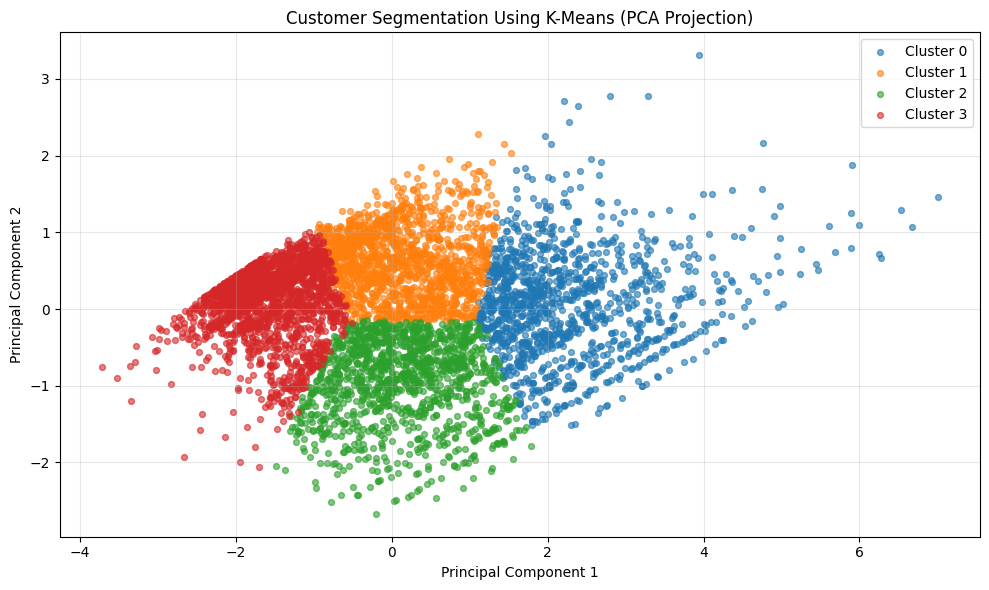

Variance explained by PC1 and PC2: 95.1 %


: 

In [ ]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce the three scaled RFM features to two dimensions
pca = PCA(n_components=2, random_state=42)
rfm_pca = pca.fit_transform(rfm_scaled)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm_scaled.index
)

# Attach the K-Means cluster labels
pca_df["KMeans_Cluster"] = rfm_segmented["KMeans_Cluster"]

# Plot the clusters
plt.figure(figsize=(10, 6))

for cluster in sorted(pca_df["KMeans_Cluster"].unique()):
    cluster_data = pca_df[pca_df["KMeans_Cluster"] == cluster]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.6,
        s=18
    )

plt.title("Customer Segmentation Using K-Means (PCA Projection)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Check how much variation the two components retain
print(
    "Variance explained by PC1 and PC2:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


In [ ]:

# Compare the two clustering approaches

from sklearn.metrics import silhouette_score

# K-Means metrics
kmeans_score = silhouette_score(rfm_scaled, rfm_segmented["KMeans_Cluster"])

# DBSCAN metrics
dbscan_cluster_count = len(set(dbscan_labels) - {-1})
dbscan_noise_count = int((dbscan_labels == -1).sum())
dbscan_noise_percentage = round(
    dbscan_noise_count / len(dbscan_labels) * 100, 2
)

print("K-MEANS")
print("Clusters:", rfm_segmented["KMeans_Cluster"].nunique())
print("Customers assigned:", rfm_segmented["KMeans_Cluster"].notna().sum())
print("Silhouette score:", round(kmeans_score, 4))

print("\nDBSCAN (eps=0.5, min_samples=5)")
print("Clusters excluding noise:", dbscan_cluster_count)
print("Noise points:", dbscan_noise_count)
print("Noise percentage:", dbscan_noise_percentage, "%")

# Confirm that DBSCAN assigned a label to every customer
print("Total DBSCAN labels:", len(dbscan_labels))


K-MEANS
Clusters: 4
Customers assigned: 5878
Silhouette score: 0.3664

DBSCAN (eps=0.5, min_samples=5)
Clusters excluding noise: 2
Noise points: 63
Noise percentage: 1.07 %
Total DBSCAN labels: 5878


: 